In [1]:
import os
os.environ["ARROW_USER_SIMD_LEVEL"] = "NONE"

import sys, json, random
import numpy as np
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, f1_score

PROJECT = os.path.expanduser("~/mlproject")
sys.path.insert(0, PROJECT)

ART = os.path.join(PROJECT, "artifacts")
MET = os.path.join(PROJECT, "metrics")
os.makedirs(MET, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

vectorizer = joblib.load(os.path.join(ART, "lab2_span_tfidf.joblib"))
model      = joblib.load(os.path.join(ART, "lab2_span_logreg.joblib"))

df_test = pd.read_parquet(os.path.join(ART, "test.parquet"))

def flatten(df):
    rows = []
    for _, r in df.iterrows():
        t = r["text"] or ""
        s = r["entity_starts"]
        if s is None: continue
        try:
            if len(s) == 0: continue
        except TypeError: continue
        for st, en, lb in zip(r["entity_starts"], r["entity_ends"], r["entity_labels"]):
            rows.append({"span": t[st:en], "label": lb})
    return pd.DataFrame(rows)

sp_te = flatten(df_test)
print(f"спанов в test: {len(sp_te)}")
print(f"классов: {sp_te['label'].nunique()}")
print(sp_te["label"].value_counts().head(10))

спанов в test: 3159
классов: 26
label
ip                579
name              300
first_name        285
date              241
address_city      232
last_name         203
mobile_phone      195
address           180
address_street    151
organization      116
Name: count, dtype: int64


In [2]:
# По 1-2 на класс, максимум 20
MAX_PER_CLASS = 2
TOTAL = 20

picked = []
for cls, group in sp_te.groupby("label"):
    n = min(len(group), MAX_PER_CLASS)
    picked.extend(group.sample(n=n, random_state=SEED).to_dict("records"))
    if len(picked) >= TOTAL:
        break
sample = pd.DataFrame(picked).head(TOTAL).reset_index(drop=True)
print(f"выбрано спанов: {len(sample)}")
print(sample)

# Предсказания на оригиналах
X0 = vectorizer.transform(sample["span"])
p0 = model.predict(X0)
conf0 = model.predict_proba(X0).max(axis=1)
sample["pred_orig"] = p0
sample["conf_orig"] = conf0
sample["correct_orig"] = (sample["pred_orig"] == sample["label"]).astype(int)

print(f"\naccuracy на оригиналах: {sample['correct_orig'].mean():.3f}")
print(f"ошибок в оригинале: {(1 - sample['correct_orig']).sum()} из {len(sample)}")

выбрано спанов: 20
                                  span                label
0   В Прилуках, на проспекте Победы 90              address
1     дома №22 по проспекту Прибрежный              address
2                                   12    address_apartment
3                                   42    address_apartment
4                     Springside Coast         address_city
5                             Новоярск         address_city
6                               France      address_country
7                              Ukraine      address_country
8                                Поділ     address_district
9                               Подолу     address_district
10                 55.0084∘N,82.9357∘E  address_geolocation
11                46.635400, 32.616900  address_geolocation
12                                  21        address_house
13                                  23        address_house
14                               95631  address_postal_code
15                   

In [3]:
import re

LAT_TO_CYR = {
    "a": "а", "e": "е", "o": "о", "c": "с", "p": "р", "x": "х", "y": "у",
    "A": "А", "E": "Е", "O": "О", "C": "С", "P": "Р", "X": "Х", "Y": "У",
}

def t_upper(s): return s.upper()
def t_title(s): return s.title()
def t_spaces(s):
    out = []
    for ch in s:
        out.append(ch)
        if ch == " ":
            out.append(" ")
    return "".join(out) or s
def t_typo_swap(s):
    if len(s) < 3: return s
    i = random.randrange(0, len(s) - 1)
    return s[:i] + s[i+1] + s[i] + s[i+2:]
def t_typo_drop(s):
    if len(s) < 3: return s
    i = random.randrange(1, len(s) - 1)
    return s[:i] + s[i+1:]
def t_homoglyph(s):
    return "".join(LAT_TO_CYR.get(ch, ch) for ch in s)

TRANSFORMS = {
    "upper":       t_upper,
    "title":       t_title,
    "spaces":      t_spaces,
    "typo_swap":   t_typo_swap,
    "typo_drop":   t_typo_drop,
    "homoglyph":   t_homoglyph,
}

In [4]:
results = {}
for name, fn in TRANSFORMS.items():
    random.seed(SEED)
    mutated = [fn(s) for s in sample["span"]]
    X = vectorizer.transform(mutated)
    pred = model.predict(X)
    conf = model.predict_proba(X).max(axis=1)

    flipped = (pred != sample["pred_orig"]).sum()
    correct = (pred == sample["label"]).astype(int)
    acc = correct.mean()

    # degradation: было правильно, стало неправильно
    deg = ((sample["correct_orig"] == 1) & (correct == 0)).sum()
    # "improvement": было неправильно, стало правильно
    imp = ((sample["correct_orig"] == 0) & (correct == 1)).sum()

    results[name] = {
        "n": len(mutated),
        "flips": int(flipped),
        "flip_rate": float(flipped / len(mutated)),
        "acc_before": float(sample["correct_orig"].mean()),
        "acc_after": float(acc),
        "delta_acc": float(acc - sample["correct_orig"].mean()),
        "degradation": int(deg),
        "improvement": int(imp),
        "examples": [
            {"orig": sample["span"].iloc[i],
             "mut":  mutated[i],
             "true": sample["label"].iloc[i],
             "pred_before": sample["pred_orig"].iloc[i],
             "pred_after":  pred[i],
             "conf_before": float(sample["conf_orig"].iloc[i]),
             "conf_after":  float(conf[i])}
            for i in range(len(mutated))
            if pred[i] != sample["pred_orig"].iloc[i]
        ][:5],  # первые 5 flip-примеров
    }

summary = pd.DataFrame({
    k: {"flip_rate": v["flip_rate"], "acc_before": v["acc_before"],
        "acc_after": v["acc_after"], "delta_acc": v["delta_acc"],
        "degradation": v["degradation"], "improvement": v["improvement"]}
    for k, v in results.items()
}).T
print(summary.round(3))

           flip_rate  acc_before  acc_after  delta_acc  degradation  \
upper           0.00         0.6       0.60       0.00          0.0   
title           0.00         0.6       0.60       0.00          0.0   
spaces          0.00         0.6       0.60       0.00          0.0   
typo_swap       0.25         0.6       0.45      -0.15          4.0   
typo_drop       0.20         0.6       0.45      -0.15          3.0   
homoglyph       0.15         0.6       0.50      -0.10          2.0   

           improvement  
upper              0.0  
title              0.0  
spaces             0.0  
typo_swap          1.0  
typo_drop          0.0  
homoglyph          0.0  


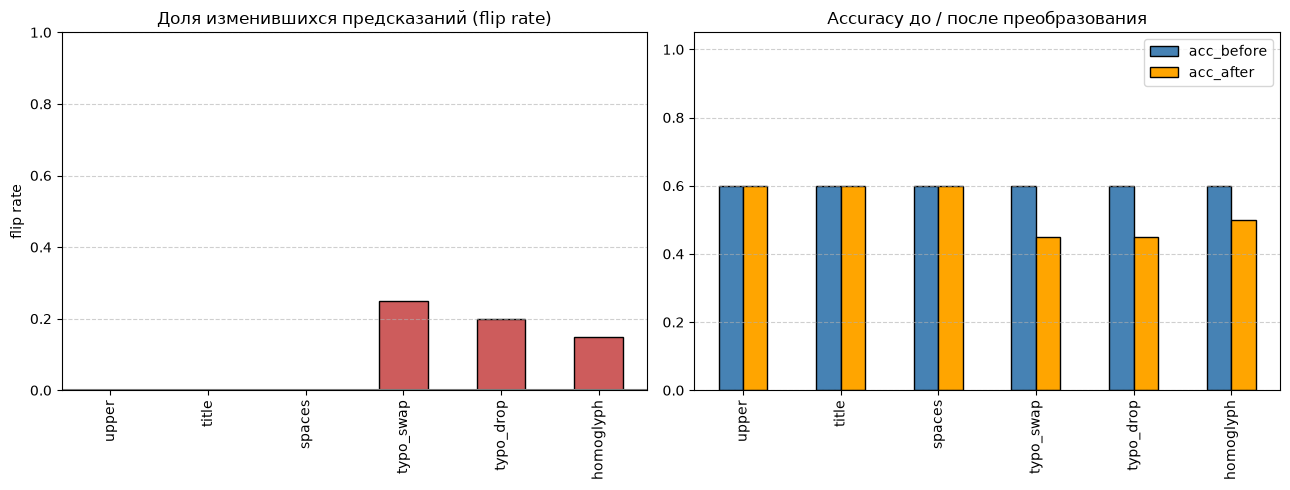

Сохранено: /home/mluser/mlproject/metrics/robustness_flip_rate.png


In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

summary["flip_rate"].plot(kind="bar", ax=ax[0], color="indianred", edgecolor="black")
ax[0].set_title("Доля изменившихся предсказаний (flip rate)")
ax[0].set_ylabel("flip rate")
ax[0].set_ylim(0, 1)
ax[0].grid(axis="y", linestyle="--", alpha=0.6)
ax[0].axhline(0, color="gray")

summary[["acc_before", "acc_after"]].plot(kind="bar", ax=ax[1],
                                          color=["steelblue", "orange"],
                                          edgecolor="black")
ax[1].set_title("Accuracy до / после преобразования")
ax[1].set_ylim(0, 1.05)
ax[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(MET, "robustness_flip_rate.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Сохранено:", os.path.join(MET, "robustness_flip_rate.png"))

In [6]:
for name, v in results.items():
    if not v["examples"]:
        print(f"\n=== {name}: flip нет ===")
        continue
    print(f"\n=== {name}: {v['flips']}/{v['n']} flip ===")
    for ex in v["examples"]:
        print(f"  orig={ex['orig']!r}")
        print(f"  mut ={ex['mut']!r}")
        print(f"  true={ex['true']}  pred: {ex['pred_before']} → {ex['pred_after']}  "
              f"conf: {ex['conf_before']:.2f} → {ex['conf_after']:.2f}")


=== upper: flip нет ===

=== title: flip нет ===

=== spaces: flip нет ===

=== typo_swap: 5/20 flip ===
  orig='дома №22 по проспекту Прибрежный'
  mut ='одма №22 по проспекту Прибрежный'
  true=address  pred: address → address_street  conf: 0.46 → 0.53
  orig='France'
  mut ='Farnce'
  true=address_country  pred: address_country → organization  conf: 0.59 → 0.15
  orig='Подолу'
  mut ='оПдолу'
  true=address_district  pred: address_district → address_city  conf: 0.80 → 0.23
  orig='95631'
  mut ='95613'
  true=address_postal_code  pred: mobile_phone → address_postal_code  conf: 0.11 → 0.29
  orig='Финского залива'
  mut ='Фниского залива'
  true=address_region  pred: address_region → address_district  conf: 0.19 → 0.16

=== typo_drop: 4/20 flip ===
  orig='дома №22 по проспекту Прибрежный'
  mut ='дма №22 по проспекту Прибрежный'
  true=address  pred: address → address_street  conf: 0.46 → 0.55
  orig='Подолу'
  mut ='Пдолу'
  true=address_district  pred: address_district → address 

In [7]:
print("=== Нетипичные входы ===\n")

atypical = [
    ("email с эмодзи",        "ivan.petrov🙂@example.com"),
    ("email с HTML",          "<b>ivan</b>@example.com"),
    ("гомоглиф email",        "ivаn.petrоv@exаmple.com"),
    ("очень длинный спан",    "x" * 999),
    ("повторяющиеся символы", "ааааааааааааааа"),
    ("полностью цифры",       "9999999999999999"),
    ("только пунктуация",     "!@#$%^&*()"),
    ("пробелы+табы",          "  \t  +7  900\t123-45-67  "),
    ("fullwidth цифры",       "+7 ９００ 123-45-67"),
]

texts = [s for _, s in atypical]
X_at = vectorizer.transform(texts)
pred_at = model.predict(X_at)
proba_at = model.predict_proba(X_at)
conf_at = proba_at.max(axis=1)
classes = model.classes_

for i, (name, s) in enumerate(atypical):
    row = proba_at[i]
    top3_idx = np.argsort(row)[::-1][:3]
    top3 = ", ".join(f"{classes[j]}:{row[j]:.2f}" for j in top3_idx)
    print(f"{name:<25} pred={pred_at[i]:<20} conf={conf_at[i]:.2f}")
    print(f"  span={s!r}")
    print(f"  top3=[{top3}]")

=== Нетипичные входы ===

email с эмодзи            pred=email                conf=0.90
  span='ivan.petrov🙂@example.com'
  top3=[email:0.90, address_region:0.01, address_city:0.01]
email с HTML              pred=email                conf=0.92
  span='<b>ivan</b>@example.com'
  top3=[email:0.92, address_city:0.01, first_name:0.01]
гомоглиф email            pred=email                conf=0.94
  span='ivаn.petrоv@exаmple.com'
  top3=[email:0.94, first_name:0.00, address_region:0.00]
очень длинный спан        pred=address_city         conf=0.11
  span='xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

In [8]:
import hashlib

report = {
    "sample_size": len(sample),
    "seed": SEED,
    "transforms": {k: {kk: vv for kk, vv in v.items() if kk != "examples"}
                   for k, v in results.items()},
    "atypical": [
        {"name": name, "span": s,
         "pred": pred_at[i], "confidence": float(conf_at[i])}
        for i, (name, s) in enumerate(atypical)
    ],
}
path = os.path.join(MET, "robustness_report.json")
with open(path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Сохранено:", path)
print(json.dumps(report["transforms"], indent=2, ensure_ascii=False))

Сохранено: /home/mluser/mlproject/metrics/robustness_report.json
{
  "upper": {
    "n": 20,
    "flips": 0,
    "flip_rate": 0.0,
    "acc_before": 0.6,
    "acc_after": 0.6,
    "delta_acc": 0.0,
    "degradation": 0,
    "improvement": 0
  },
  "title": {
    "n": 20,
    "flips": 0,
    "flip_rate": 0.0,
    "acc_before": 0.6,
    "acc_after": 0.6,
    "delta_acc": 0.0,
    "degradation": 0,
    "improvement": 0
  },
  "spaces": {
    "n": 20,
    "flips": 0,
    "flip_rate": 0.0,
    "acc_before": 0.6,
    "acc_after": 0.6,
    "delta_acc": 0.0,
    "degradation": 0,
    "improvement": 0
  },
  "typo_swap": {
    "n": 20,
    "flips": 5,
    "flip_rate": 0.25,
    "acc_before": 0.6,
    "acc_after": 0.45,
    "delta_acc": -0.14999999999999997,
    "degradation": 4,
    "improvement": 1
  },
  "typo_drop": {
    "n": 20,
    "flips": 4,
    "flip_rate": 0.2,
    "acc_before": 0.6,
    "acc_after": 0.45,
    "delta_acc": -0.14999999999999997,
    "degradation": 3,
    "improvement":